# ETF long / flat / short · v4.0

Fifteen separate ETF accounts and two explicitly different equal-capital portfolio methods.
The main measure is **daily Sharpe after transaction fees, before borrowing costs**.
Primary fees are 5 bps one way on actual traded notional. **Short borrowing interest,
cash yield and interest on short proceeds are all zero by user request.**

Historical evaluation ends in December 2023. **2024 onward remains reserved.**
These repeatedly inspected historical results are exploratory, with no promotion rule.


In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
from IPython.display import display, HTML
%matplotlib inline
ROOT = Path.cwd()
assert (ROOT / 'config.json').is_file(), 'Run from the v4_0 folder.'
sys.path.insert(0, str(ROOT / 'src'))
from report_views import LongShortReport
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9, 'axes.titlepad': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
R = LongShortReport(ROOT)


## What changed and what remains inherited

The annual ETF-context trees, horizon/target/recipe choices and position-sizing rules are inherited
from the frozen v3.1 study. This extension fits **two directional payoff mappings using earlier
matured out-of-fold forecasts**, keeping saved prediction-bin edges. The short outcome is the
negative gross horizon return less its own label cost; it is not the negative of an already-net
long outcome. A side must have positive expected payoff; unsupported, tied or unqualified cases stay flat.

Decisions use the completed weekly close and execute at the next actual open. Short proceeds remain
cash. Synthetic adjusted prices approximate total return, with no second distribution credit/debit.
This is a research short proxy: actual locates, recalls, stock-loan distributions, changing broker
requirements and exchange price-test execution have not been reconstructed.


## Individual account overview

In [2]:
display(HTML(R.overview()))

ETF,Long / flat / short Sharpe,Long / cash control Sharpe,ETF buy & hold Sharpe,SPY buy & hold Sharpe,completed episodes,episode win rate,L/F/S max drawdown
XLK,0.3374,0.5101,0.7280,0.5691,58,46.6%,-34.6%
XLF,-0.0715,0.3357,0.3230,0.5691,32,53.1%,-88.3%
XLE,0.2890,0.3070,0.2710,0.5691,105,61.0%,-60.5%
XLV,0.2184,0.5370,0.6681,0.5691,47,59.6%,-32.1%
XLI,0.3984,0.4655,0.5113,0.5691,50,58.0%,-45.0%
XLY,0.3329,0.5297,0.6462,0.5691,27,33.3%,-54.0%
XLP,0.4820,0.5579,0.6472,0.5691,57,59.6%,-24.2%
XLU,0.1006,0.2835,0.4065,0.5691,46,50.0%,-43.1%
XLB,0.4912,0.5220,0.4007,0.5691,102,57.8%,-24.7%
IEF,0.3828,0.3828,0.4316,0.5691,48,43.8%,-23.3%


## Measured changes and research implications

In [3]:
display(HTML(R.observations()))

## Primary portfolio · weekly equal capital

Each ETF receives a fixed one-fifteenth capital budget. Its signed model target is divided by 15;
flat budgets remain cash and are not redistributed. Orders jointly solve the post-fee NAV target.
Positions drift between weekly executions. The common period is January 9, 2012–December 29, 2023.

The chart compares this procedure with weekly long/cash trees, weekly equal-weight ETF holdings,
initial equal-weight ETF holdings without inter-ETF rebalancing, and SPY. These are different
investment rules; benchmark names preserve that distinction.


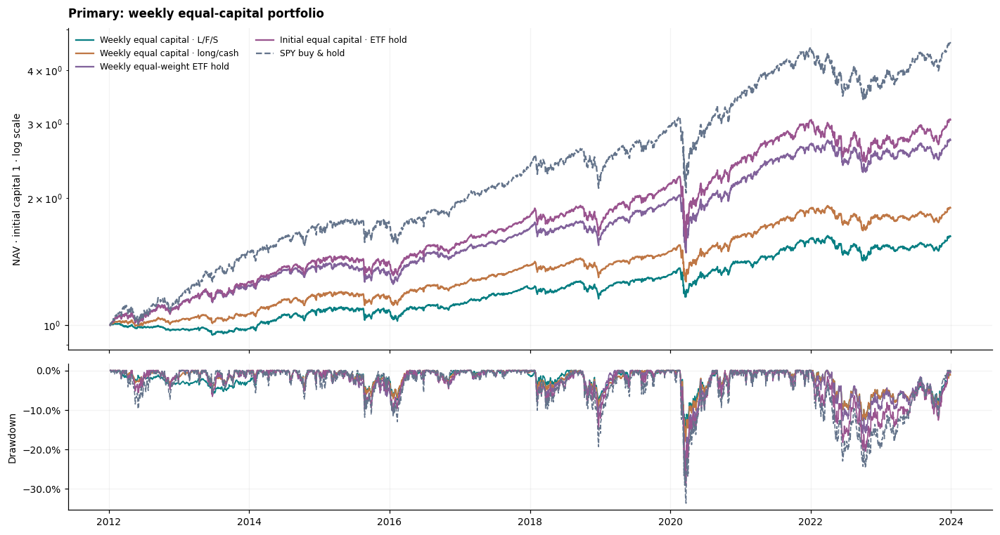

In [4]:
R.portfolio_figure(secondary=False)

In [5]:
display(HTML(R.portfolio_tables()))

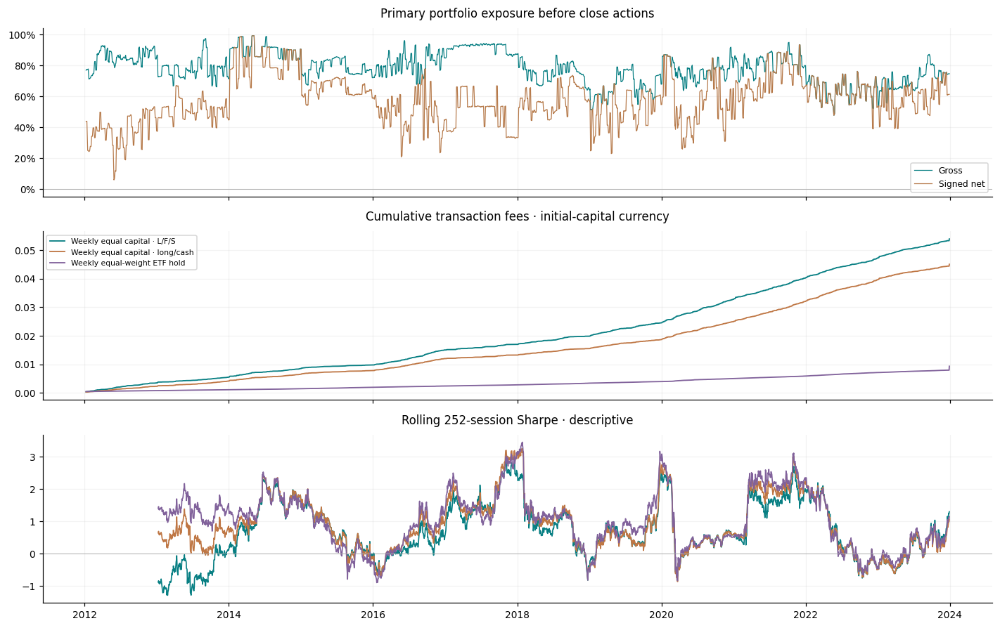

In [6]:
R.portfolio_diagnostics()

## Secondary portfolio · initial equal capital, drifting sleeves

The same initial capital is split across 15 independent accounts. There are no later inter-sleeve
transfers; total NAV is the sum of the common-period sleeve NAVs divided by 15. This portfolio
therefore differs from weekly one-fifteenth target budgets. The accounts are independently
simulated; that does not imply statistically independent returns.


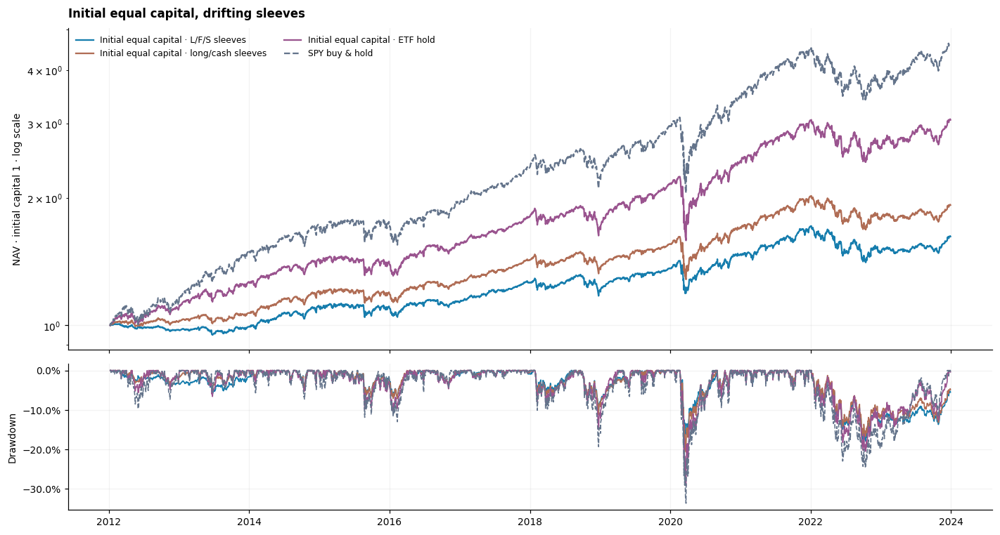

In [7]:
R.portfolio_figure(secondary=True)

## Paired uncertainty · fixed fitted strategies

In [8]:
display(HTML(R.uncertainty_tables()))

scope,ticker,strategy,benchmark,start,end,variant,baseline_variant,variant_sharpe,baseline_sharpe,delta_sharpe,delta_sharpe_95pct_low,delta_sharpe_95pct_high,p_centered_bootstrap_one_sided_approx,annualized_mean_daily_return_difference,annualized_mean_daily_return_difference_95pct_low,annualized_mean_daily_return_difference_95pct_high,bootstrap_replications,block_sessions,seed,uncertainty_caveat,p_holm,multiplicity_family_size
individual,XLK,long_short,long_only,2008-01-07,2023-12-29,long_short,baseline,0.3374,0.5101,-0.1727,-0.2904,-0.0827,0.9973,-0.0286,-0.0457,-0.0132,9999,20,42,Exploratory historical comparison of fixed fitted strategies. Joint paired blocks retain cross-arm pairing; fits/selection are not replayed. Raw intervals are unadjusted. Approximate centered-bootstrap p-values and Holm adjustment do not establish prospective significance.,1.0000,52
individual,XLK,long_short,etf_hold,2008-01-07,2023-12-29,long_short,baseline,0.3374,0.7280,-0.3906,-0.7011,-0.1123,0.9946,-0.1095,-0.1721,-0.0527,9999,20,42,Exploratory historical comparison of fixed fitted strategies. Joint paired blocks retain cross-arm pairing; fits/selection are not replayed. Raw intervals are unadjusted. Approximate centered-bootstrap p-values and Holm adjustment do not establish prospective significance.,1.0000,52
individual,XLK,long_short,spy_hold,2008-01-07,2023-12-29,long_short,baseline,0.3374,0.5691,-0.2317,-0.5942,0.1020,0.8950,-0.0559,-0.1201,0.0050,9999,20,42,Exploratory historical comparison of fixed fitted strategies. Joint paired blocks retain cross-arm pairing; fits/selection are not replayed. Raw intervals are unadjusted. Approximate centered-bootstrap p-values and Holm adjustment do not establish prospective significance.,1.0000,52
individual,XLF,long_short,long_only,2008-01-07,2023-12-29,long_short,baseline,-0.0715,0.3357,-0.4072,-0.8021,-0.0197,0.9781,-0.0679,-0.1517,0.0125,9999,20,42,Exploratory historical comparison of fixed fitted strategies. Joint paired blocks retain cross-arm pairing; fits/selection are not replayed. Raw intervals are unadjusted. Approximate centered-bootstrap p-values and Holm adjustment do not establish prospective significance.,1.0000,52
individual,XLF,long_short,etf_hold,2008-01-07,2023-12-29,long_short,baseline,-0.0715,0.3230,-0.3945,-1.0001,0.1980,0.8953,-0.1208,-0.2968,0.0460,9999,20,42,Exploratory historical comparison of fixed fitted strategies. Joint paired blocks retain cross-arm pairing; fits/selection are not replayed. Raw intervals are unadjusted. Approximate centered-bootstrap p-values and Holm adjustment do not establish prospective significance.,1.0000,52
individual,XLF,long_short,spy_hold,2008-01-07,2023-12-29,long_short,baseline,-0.0715,0.5691,-0.6406,-1.2565,-0.0666,0.9795,-0.1330,-0.2684,-0.0061,9999,20,42,Exploratory historical comparison of fixed fitted strategies. Joint paired blocks retain cross-arm pairing; fits/selection are not replayed. Raw intervals are unadjusted. Approximate centered-bootstrap p-values and Holm adjustment do not establish prospective significance.,1.0000,52
individual,XLE,long_short,long_only,2008-01-07,2023-12-29,long_short,baseline,0.2890,0.3070,-0.0180,-0.2892,0.2355,0.5214,0.0122,-0.0501,0.0786,9999,20,42,Exploratory historical comparison of fixed fitted strategies. Joint paired blocks retain cross-arm pairing; fits/selection are not replayed. Raw intervals are unadjusted. Approximate centered-bootstrap p-values and Holm adjustment do not establish prospective significance.,1.0000,52
individual,XLE,long_short,etf_hold,2008-01-07,2023-12-29,long_short,baseline,0.2890,0.2710,0.0180,-0.5185,0.5339,0.4502,-0.0120,-0.1613,0.1425,9999,20,42,Exploratory historical comparison of fixed fitted strategies. Joint paired blocks retain cross-arm pairing; fits/selection are not replayed. Raw intervals are unadjusted. Approximate centered-bootstrap p-values and Holm adjustment do not establish prospective significance.,1.0000,52
individual,XLE,long_short,spy_hold,2008-01-07,

## Transaction-cost robustness

In [9]:
display(HTML(R.cost_tables()))

scope,ticker,strategy,cost_bps,start,end,sessions,days,calendar_days,session_years,total_return,cagr,volatility,sharpe,sortino,max_drawdown,calmar,average_exposure,average_signed_exposure,average_absolute_exposure,average_gross_exposure,long_session_fraction,short_session_fraction,flat_session_fraction,turnover,turnover_per_year,cost_normalized_currency,transaction_cost,trade_events,margin_calls,long_pnl,short_pnl,borrow_cost,cash_interest,short_proceeds_interest,failed_account,annualization_sessions,risk_free_annual
individual,XLK,long_short,5,2008-01-07,2023-12-29,4024,4024,5836,15.9683,102.3%,4.5%,17.8%,0.3374,0.4740,-34.6%,0.1305,59.6%,59.6%,73.4%,73.4%,84.9%,10.9%,4.2%,102.7328,6.4336,0.0427,0.0427,454,0,1.4243,-0.3591,0.0000,0.0000,0.0000,False,252,0.0000
individual,XLK,long_only,5,2008-01-07,2023-12-29,4024,4024,5836,15.9683,223.0%,7.6%,17.4%,0.5101,0.7207,-33.6%,0.2270,66.5%,66.5%,66.5%,66.5%,84.9%,0.0%,15.1%,64.4111,4.0337,0.0369,0.0369,383,0,2.2671,0.0000,0.0000,0.0000,0.0000,False,252,0.0000
individual,XLK,etf_hold,5,2008-01-07,2023-12-29,4024,4024,5836,15.9683,869.6%,15.3%,23.3%,0.7280,1.0439,-47.9%,0.3188,100.0%,100.0%,100.0%,100.0%,100.0%,0.0%,0.0%,1.9995,0.1252,0.0054,0.0054,2,0,8.7013,0.0000,0.0000,0.0000,0.0000,False,252,0.0000
individual,XLK,spy_hold,5,2008-01-07,2023-12-29,4024,4024,5836,15.9683,356.3%,10.0%,20.4%,0.5691,0.8010,-51.5%,0.1937,100.0%,100.0%,100.0%,100.0%,100.0%,0.0%,0.0%,1.9995,0.1252,0.0028,0.0028,2,0,3.5661,0.0000,0.0000,0.0000,0.0000,False,252,0.0000
individual,XLK,long_short,0,2008-01-07,2023-12-29,4024,4024,5836,15.9683,112.9%,4.8%,17.8%,0.3555,0.4998,-33.6%,0.1444,59.6%,59.6%,73.4%,73.4%,84.9%,10.9%,4.2%,102.7683,6.4358,0.0000,0.0000,454,0,1.4968,-0.3676,0.0000,0.0000,0.0000,False,252,0.0000
individual,XLK,long_only,0,2008-01-07,2023-12-29,4024,4024,5836,15.9683,233.6%,7.8%,17.4%,0.5218,0.7373,-33.6%,0.2335,66.5%,66.5%,66.5%,66.5%,84.9%,0.0%,15.1%,64.4235,4.0345,0.0000,0.0000,383,0,2.3359,0.0000,0.0000,0.0000,0.0000,False,252,0.0000
individual,XLK,etf_hold,0,2008-01-07,2023-12-29,4024,4024,5836,15.9683,870.6%,15.3%,23.3%,0.7283,1.0443,-47.9%,0.3190,100.0%,100.0%,100.0%,100.0%,100.0%,0.0%,0.0%,2.0000,0.1252,0.0000,0.0000,2,0,8.7057,0.0000,0.0000,0.0000,0.0000,False,252,0.0000
individual,XLK,spy_hold,0,2008-01-07,2023-12-29,4024,4024,5836,15.9683,356.8%,10.0%,20.4%,0.5694,0.8015,-51.5%,0.1939,100.0%,100.0%,100.0%,100.0%,100.0%,0.0%,0.0%,2.0000,0.1252,0.0000,0.0000,2,0,3.5679,0.0000,0.0000,0.0000,0.0000,False,252,0.0000
individual,XLK,long_short,10,2008-01-07,2023-12-29,4024,4024,5836,15.9683,92.1%,4.2%,17.8%,0.3193,0.4483,-36.4%,0.1147,59.6%,59.6%,73.4%,73.4%,84.9%,10.9%,4.2%,102.6974,6.4313,0.0831,0.0831,454,0,1.3553,-0.3509,0.0000,0.0000,0.0000,False,252,0.0000
individual,XLK,long_only,10,2008-01-07,2023-12-29,4024,4024,5836,15.9683,212.8%,7.4%,17.4%,0.4985,0.7041,-33.6%,0.2206,66.5%,66.5%,66.5%,66.5%,84.9%,0.0%,15.1%,64.3987,4.0329,0.0724,0.0724,383,0,2.2002,0.0000,0.0000,0.0000,0.0000,False,252,0.0000


## XLK · account, trades and model context

All four accounts use matching dates within this ETF. Equity starts at NAV 1 immediately before the first included open; first-session returns and fees are retained.

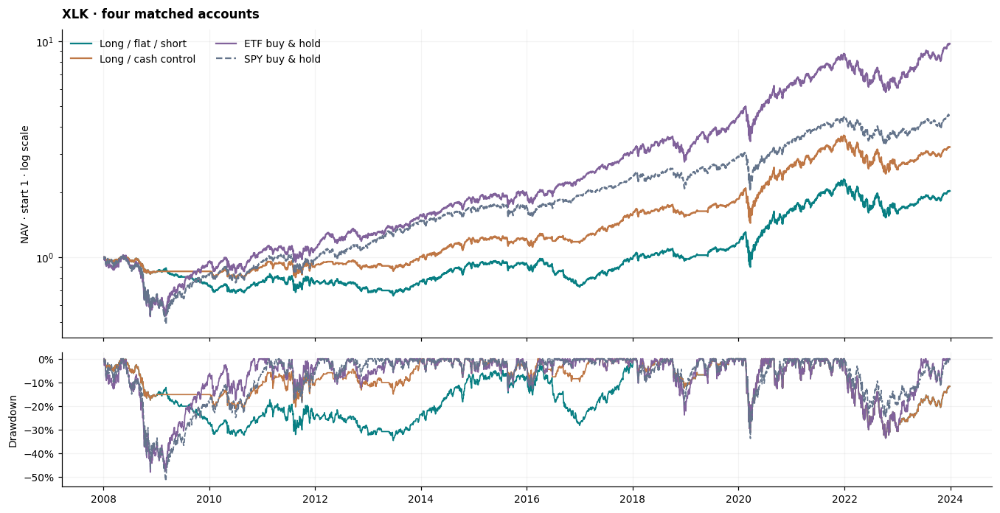

In [10]:
R.equity_figure('XLK')

In [11]:
display(HTML(R.individual_details('XLK')))

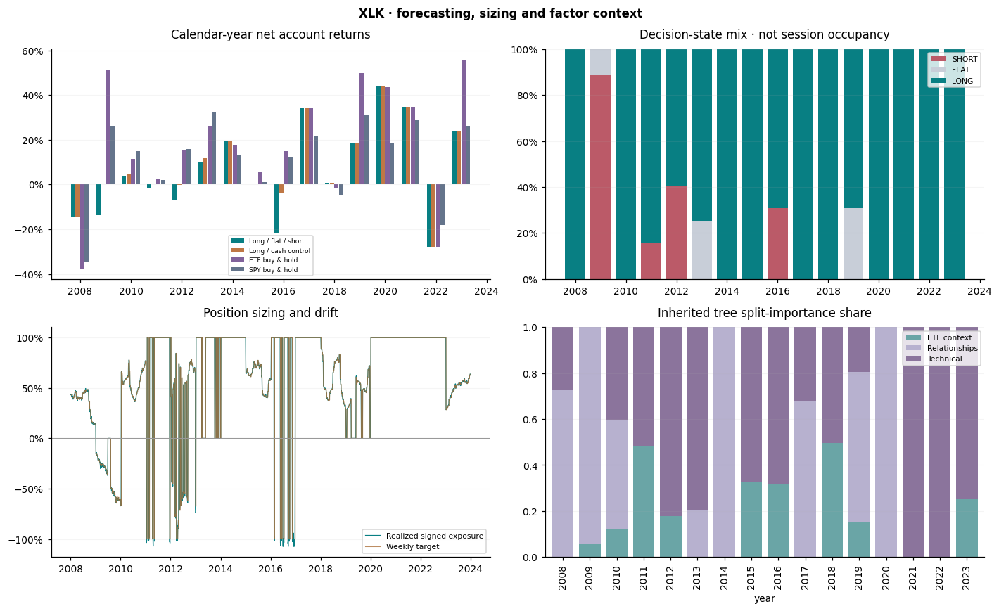

In [12]:
R.individual_diagnostics('XLK')

## XLF · account, trades and model context

All four accounts use matching dates within this ETF. Equity starts at NAV 1 immediately before the first included open; first-session returns and fees are retained.

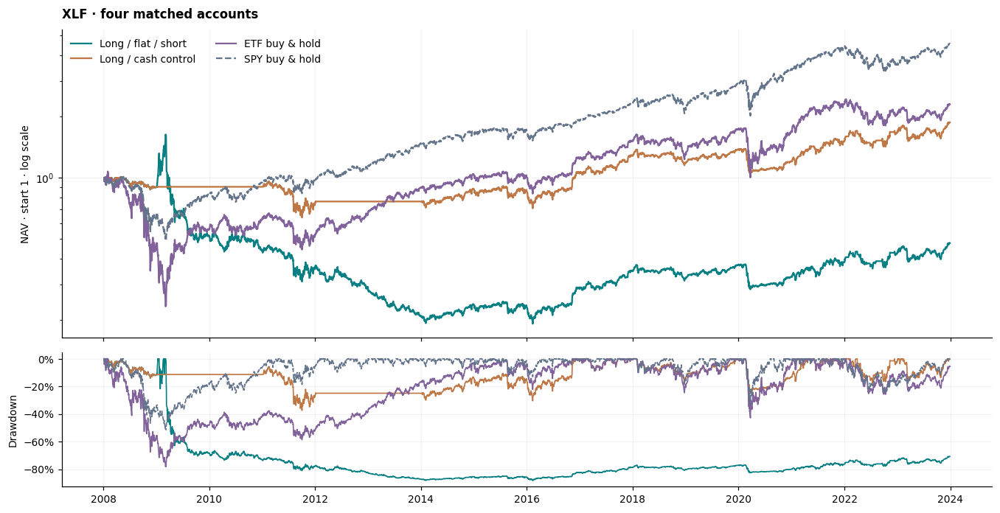

In [13]:
R.equity_figure('XLF')

In [14]:
display(HTML(R.individual_details('XLF')))

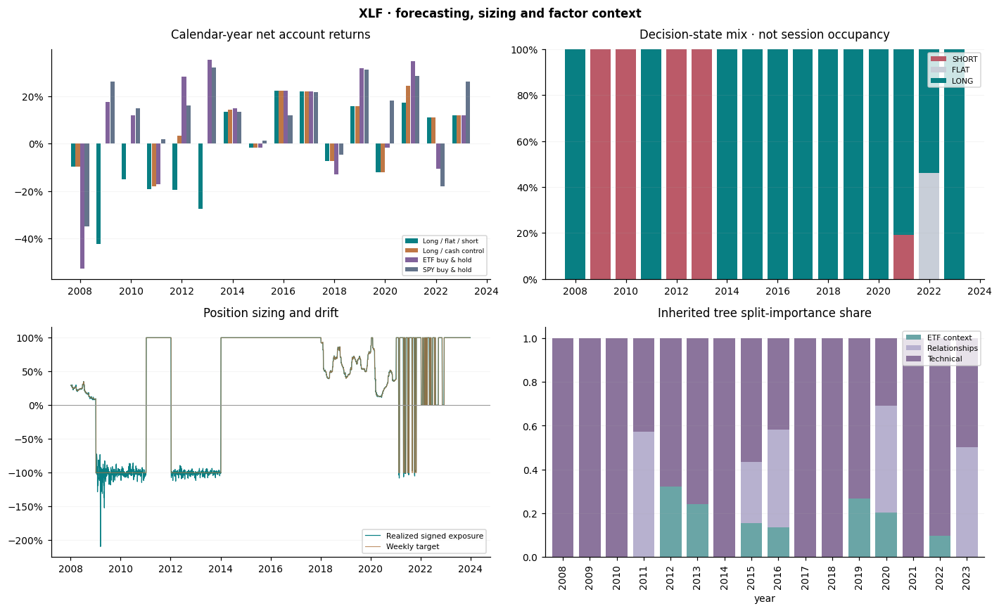

In [15]:
R.individual_diagnostics('XLF')

## XLE · account, trades and model context

All four accounts use matching dates within this ETF. Equity starts at NAV 1 immediately before the first included open; first-session returns and fees are retained.

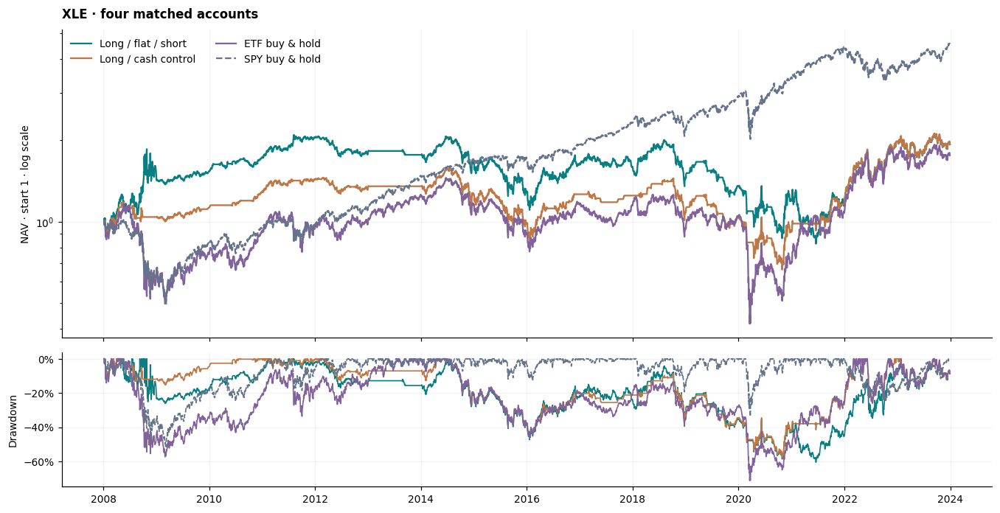

In [16]:
R.equity_figure('XLE')

In [17]:
display(HTML(R.individual_details('XLE')))

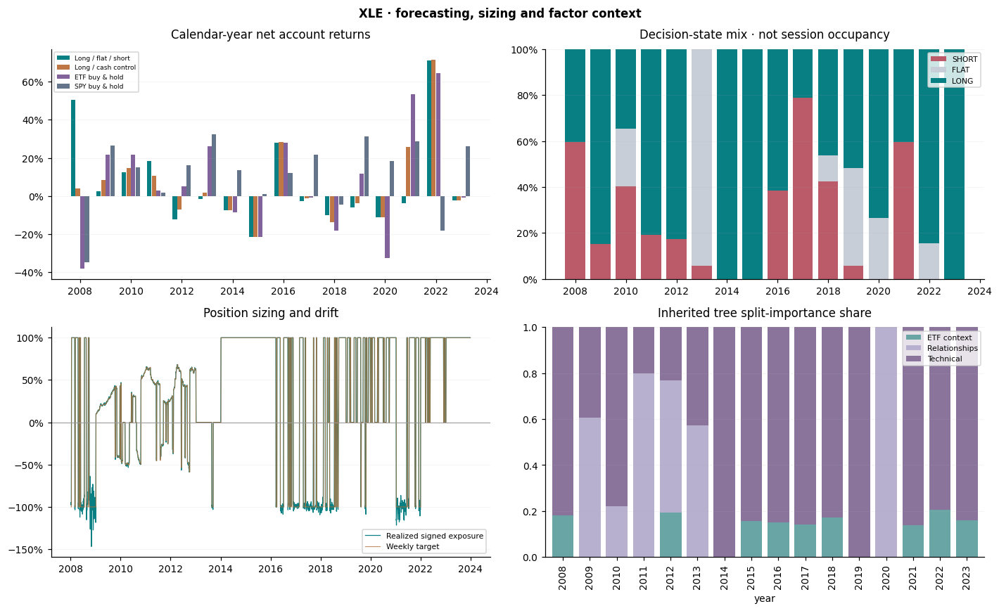

In [18]:
R.individual_diagnostics('XLE')

## XLV · account, trades and model context

All four accounts use matching dates within this ETF. Equity starts at NAV 1 immediately before the first included open; first-session returns and fees are retained.

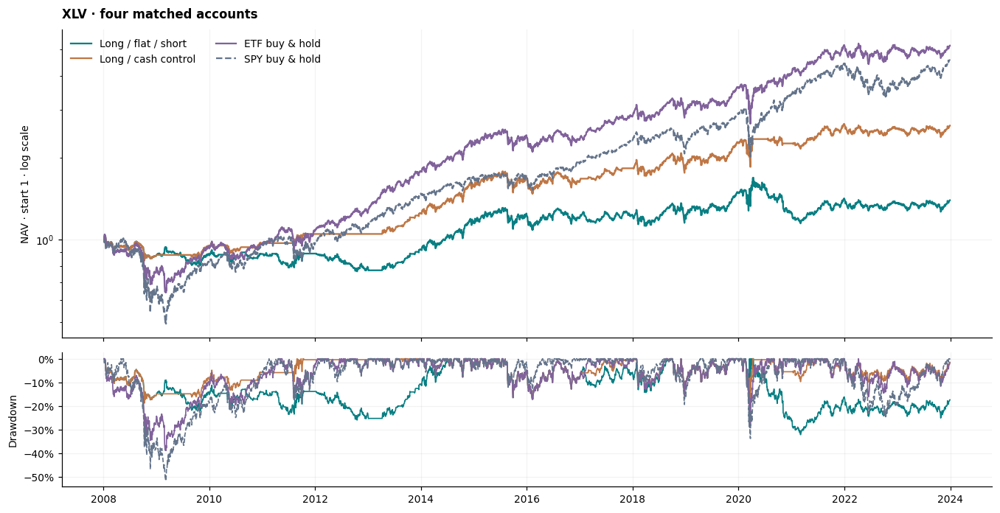

In [19]:
R.equity_figure('XLV')

In [20]:
display(HTML(R.individual_details('XLV')))

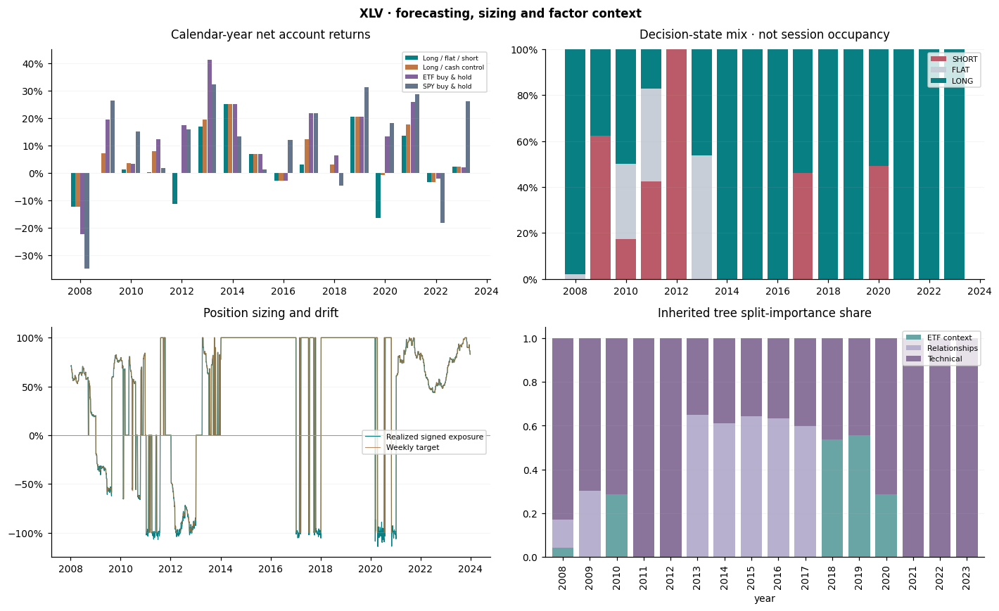

In [21]:
R.individual_diagnostics('XLV')

## XLI · account, trades and model context

All four accounts use matching dates within this ETF. Equity starts at NAV 1 immediately before the first included open; first-session returns and fees are retained.

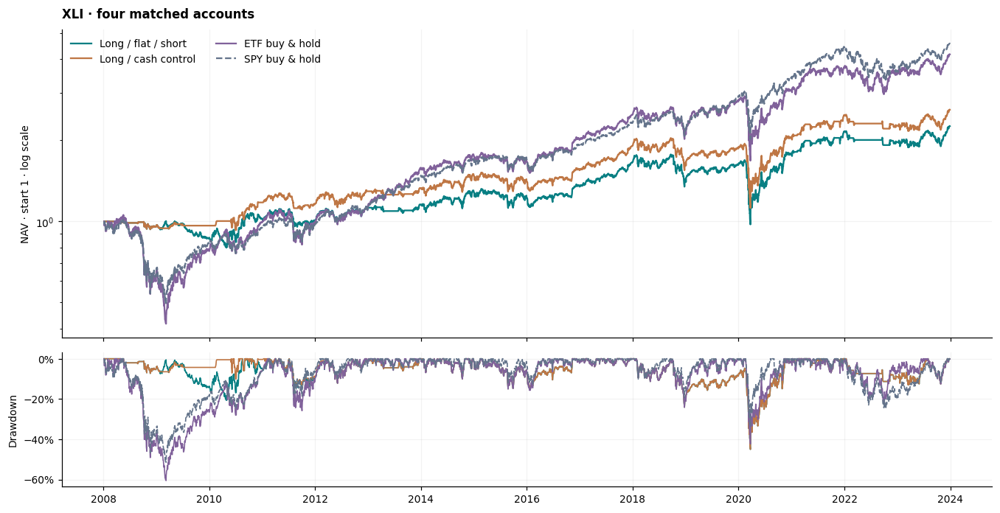

In [22]:
R.equity_figure('XLI')

In [23]:
display(HTML(R.individual_details('XLI')))

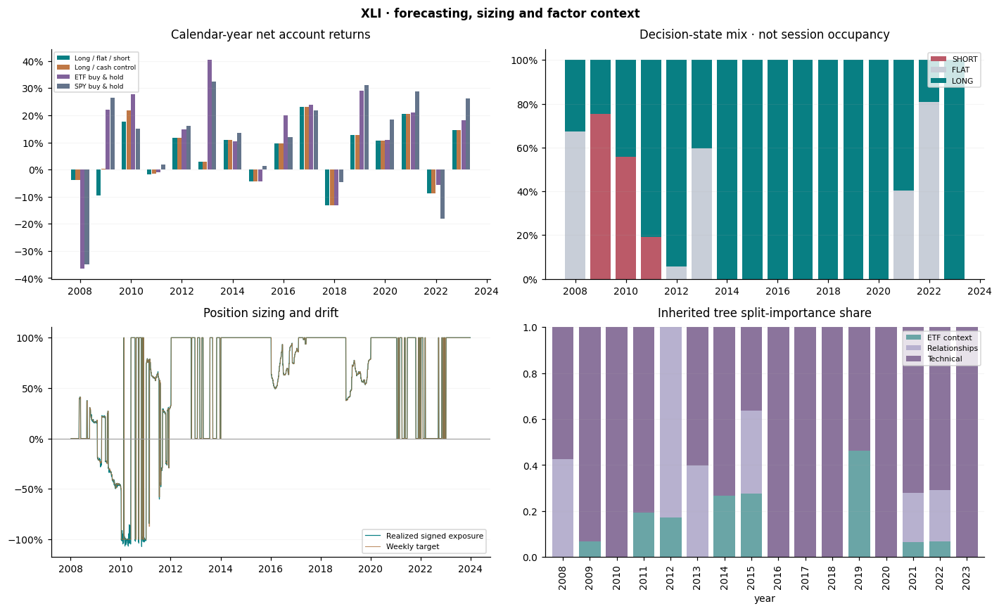

In [24]:
R.individual_diagnostics('XLI')

## XLY · account, trades and model context

All four accounts use matching dates within this ETF. Equity starts at NAV 1 immediately before the first included open; first-session returns and fees are retained.

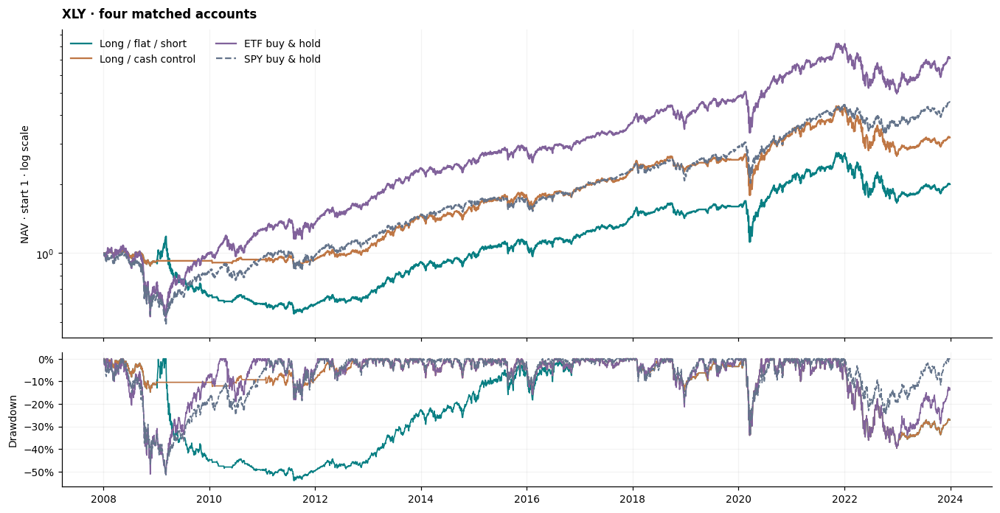

In [25]:
R.equity_figure('XLY')

In [26]:
display(HTML(R.individual_details('XLY')))

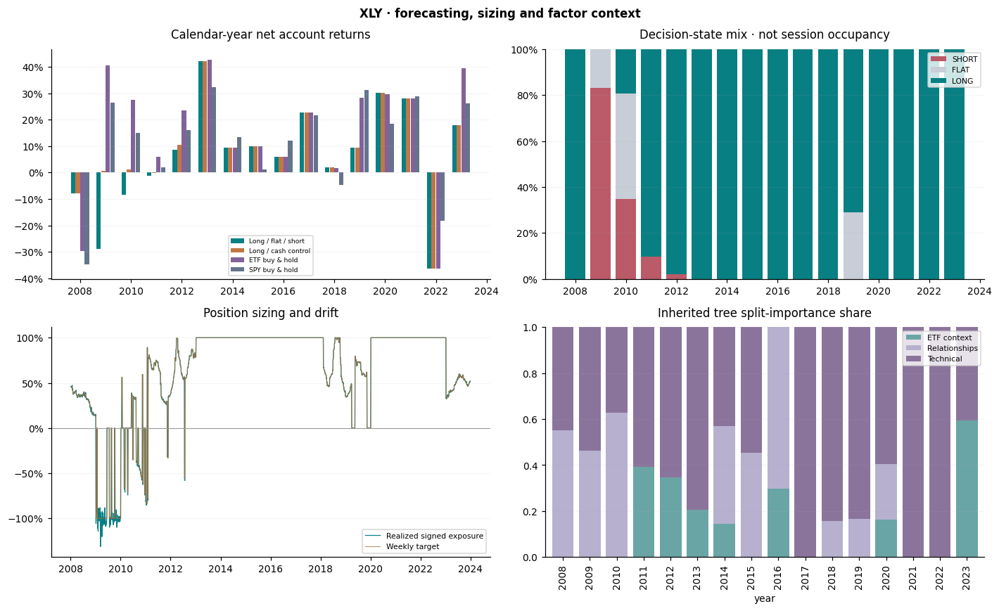

In [27]:
R.individual_diagnostics('XLY')

## XLP · account, trades and model context

All four accounts use matching dates within this ETF. Equity starts at NAV 1 immediately before the first included open; first-session returns and fees are retained.

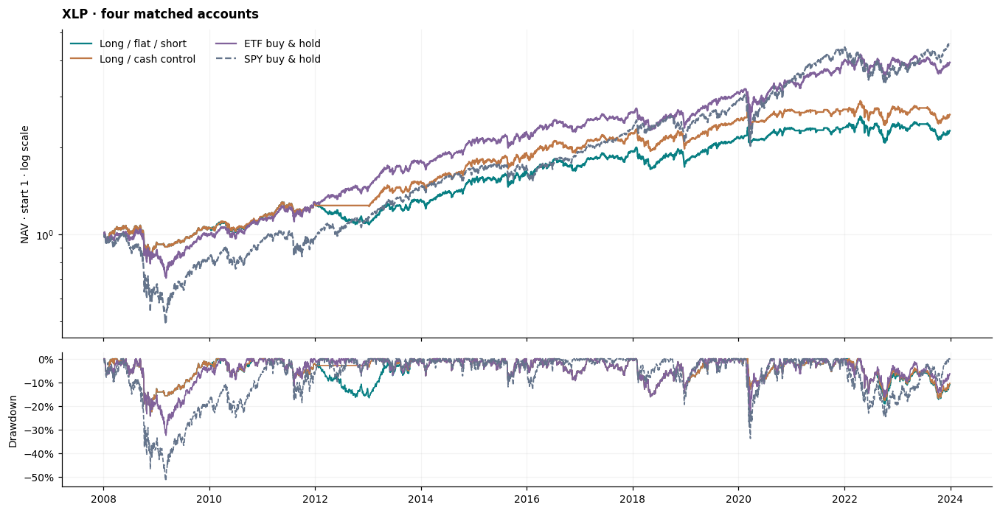

In [28]:
R.equity_figure('XLP')

In [29]:
display(HTML(R.individual_details('XLP')))

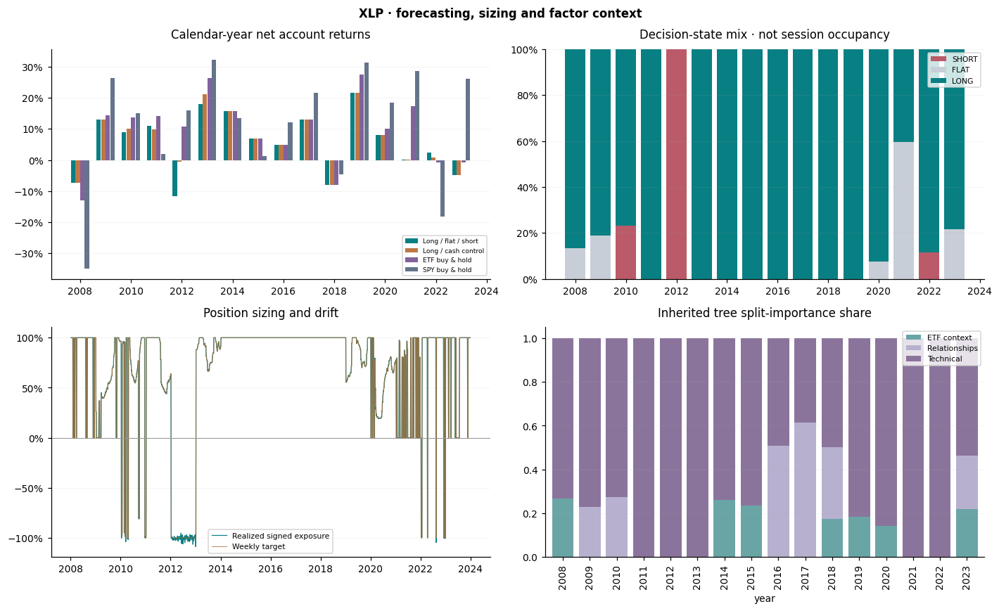

In [30]:
R.individual_diagnostics('XLP')

## XLU · account, trades and model context

All four accounts use matching dates within this ETF. Equity starts at NAV 1 immediately before the first included open; first-session returns and fees are retained.

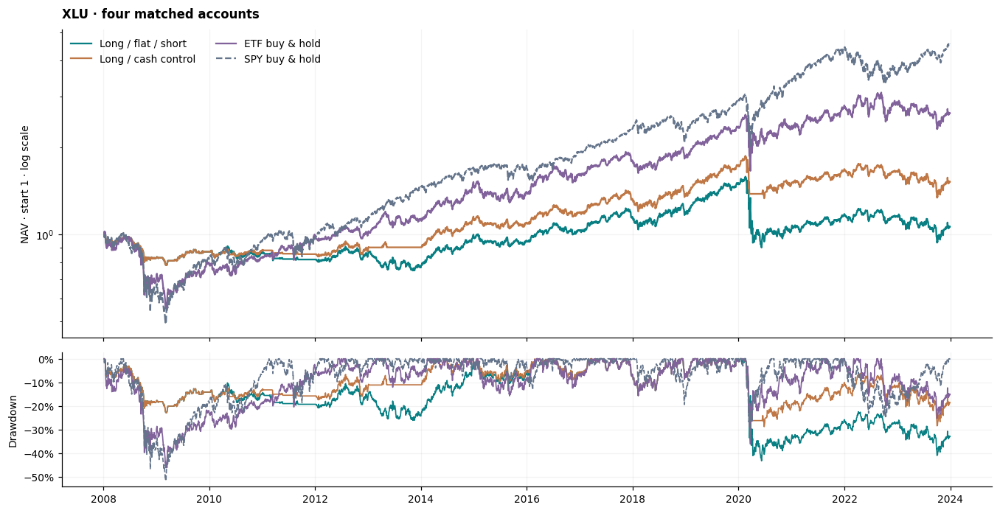

In [31]:
R.equity_figure('XLU')

In [32]:
display(HTML(R.individual_details('XLU')))

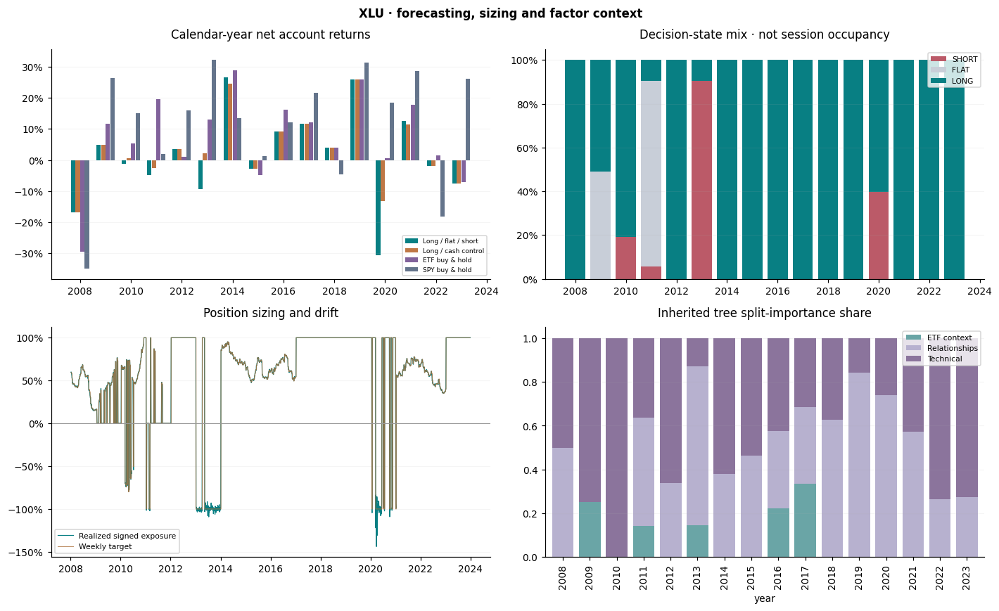

In [33]:
R.individual_diagnostics('XLU')

## XLB · account, trades and model context

All four accounts use matching dates within this ETF. Equity starts at NAV 1 immediately before the first included open; first-session returns and fees are retained.

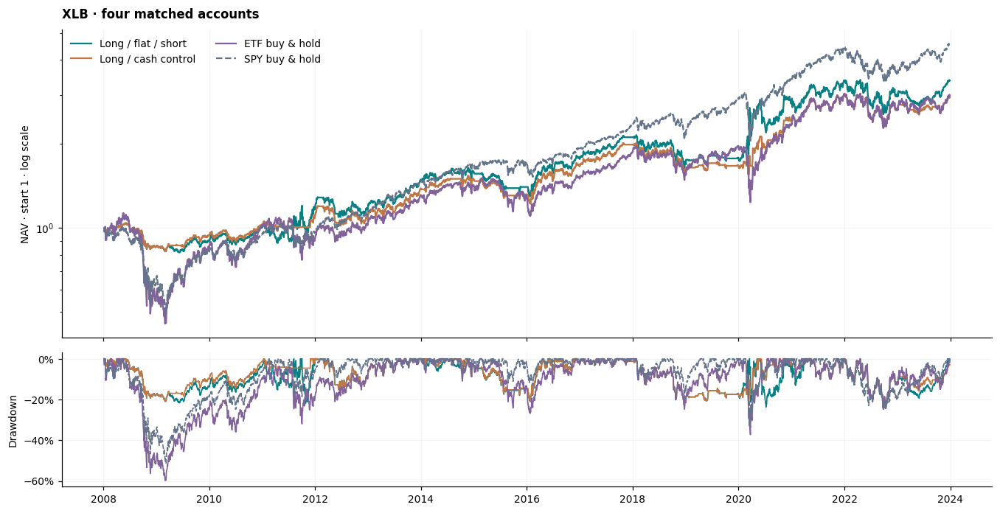

In [34]:
R.equity_figure('XLB')

In [35]:
display(HTML(R.individual_details('XLB')))

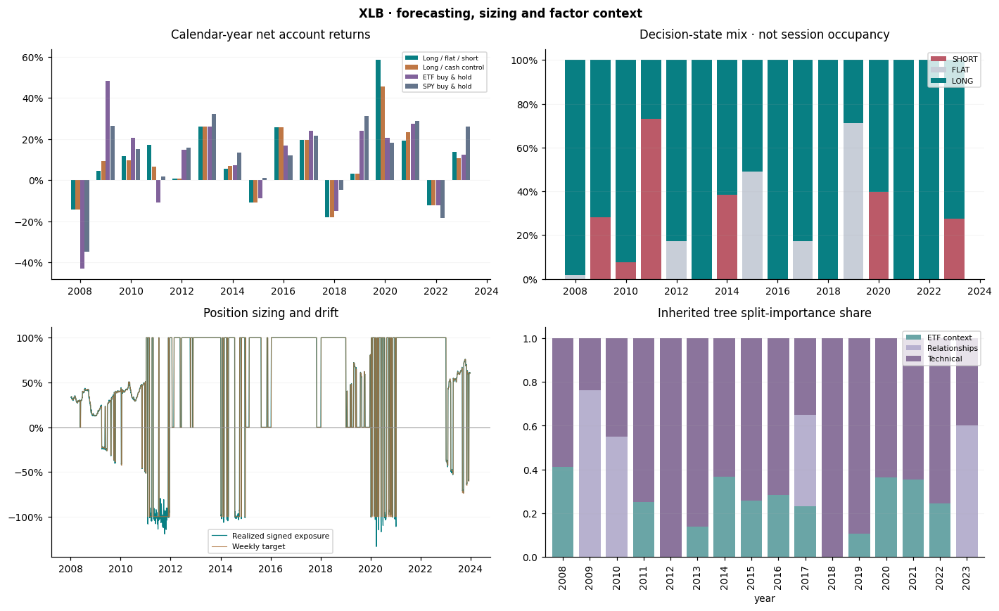

In [36]:
R.individual_diagnostics('XLB')

## IEF · account, trades and model context

All four accounts use matching dates within this ETF. Equity starts at NAV 1 immediately before the first included open; first-session returns and fees are retained.

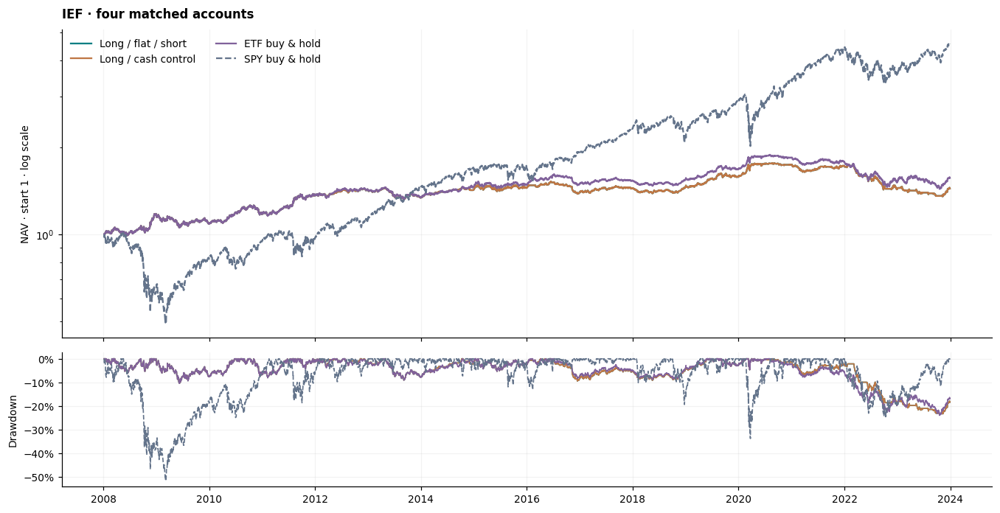

In [37]:
R.equity_figure('IEF')

In [38]:
display(HTML(R.individual_details('IEF')))

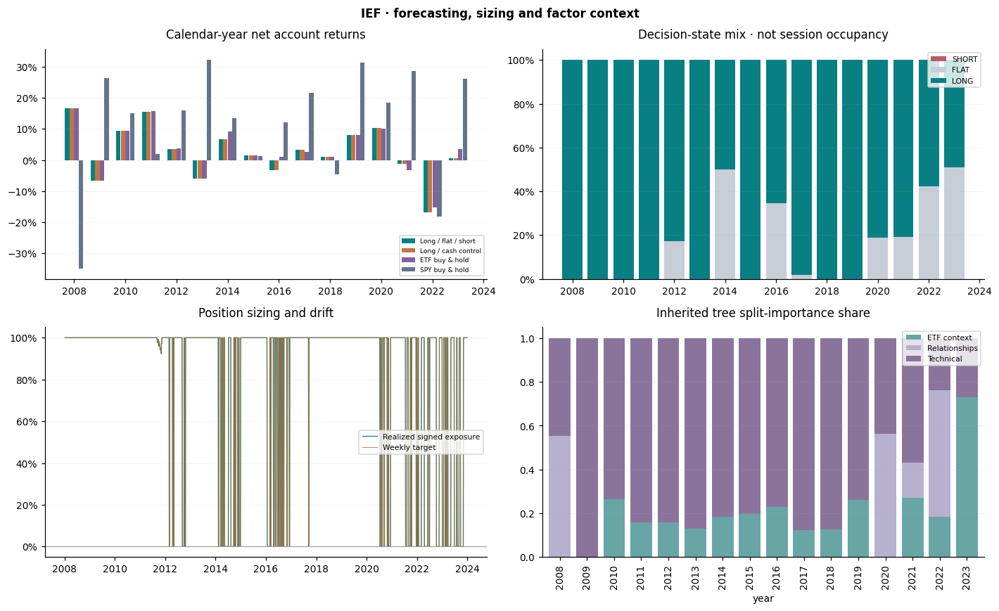

In [39]:
R.individual_diagnostics('IEF')

## TLT · account, trades and model context

All four accounts use matching dates within this ETF. Equity starts at NAV 1 immediately before the first included open; first-session returns and fees are retained.

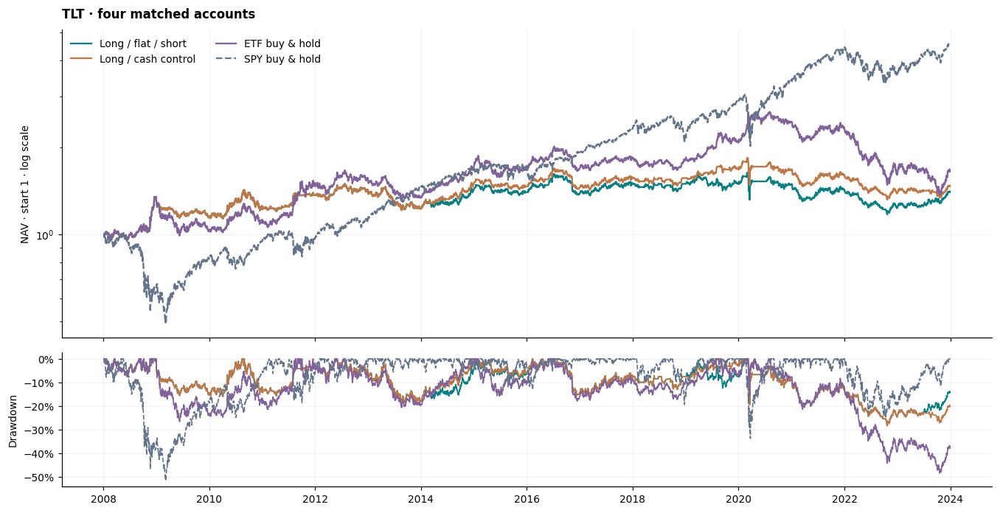

In [40]:
R.equity_figure('TLT')

In [41]:
display(HTML(R.individual_details('TLT')))

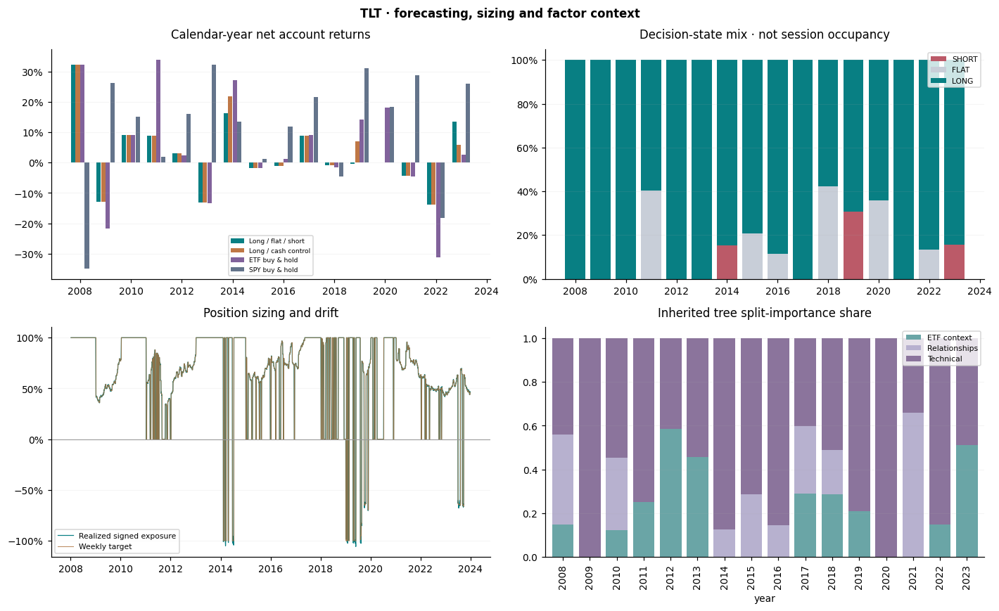

In [42]:
R.individual_diagnostics('TLT')

## TIP · account, trades and model context

All four accounts use matching dates within this ETF. Equity starts at NAV 1 immediately before the first included open; first-session returns and fees are retained.

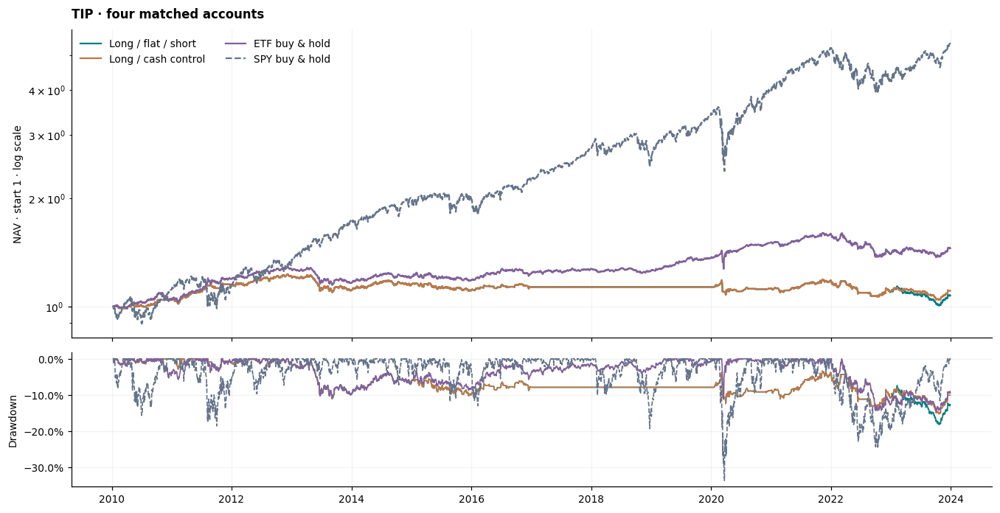

In [43]:
R.equity_figure('TIP')

In [44]:
display(HTML(R.individual_details('TIP')))

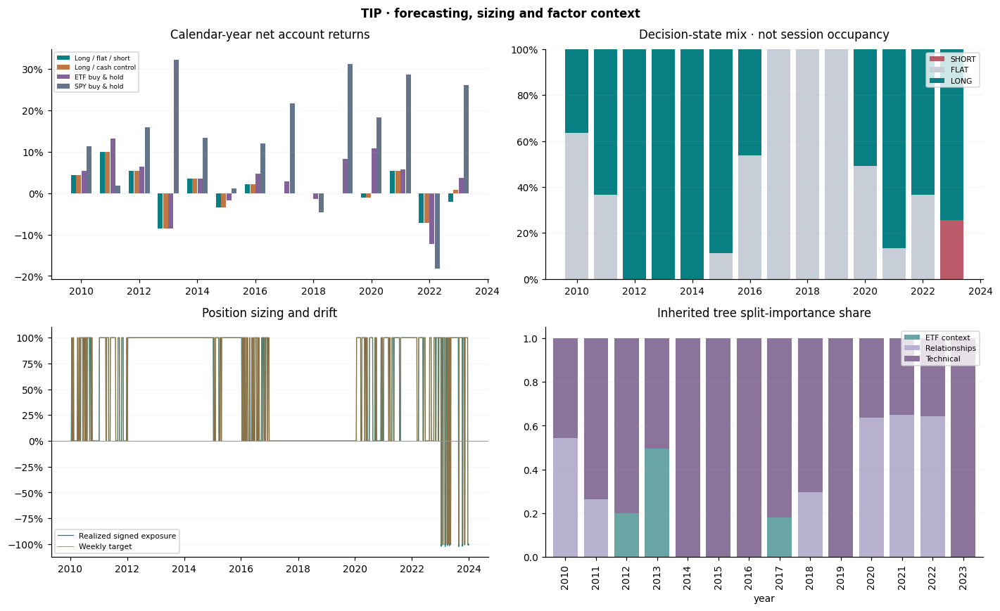

In [45]:
R.individual_diagnostics('TIP')

## GLD · account, trades and model context

All four accounts use matching dates within this ETF. Equity starts at NAV 1 immediately before the first included open; first-session returns and fees are retained.

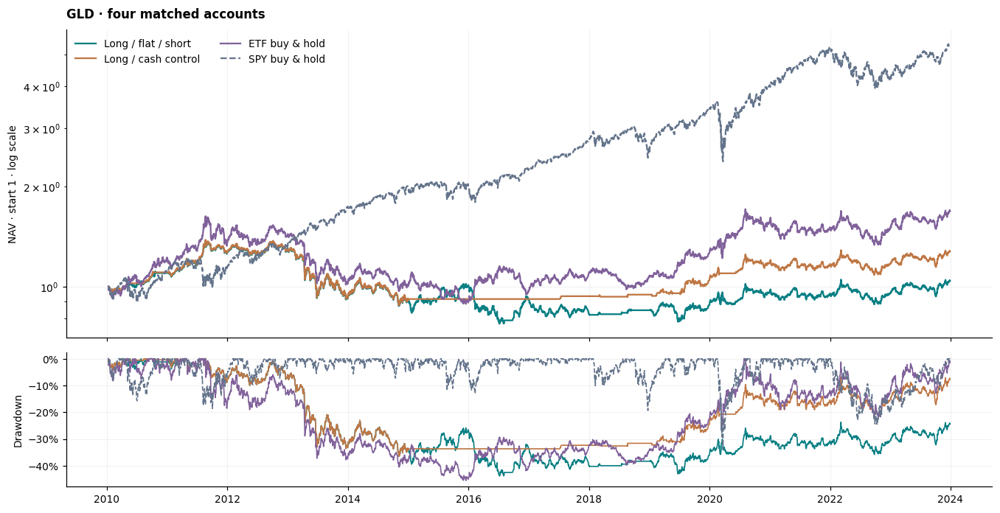

In [46]:
R.equity_figure('GLD')

In [47]:
display(HTML(R.individual_details('GLD')))

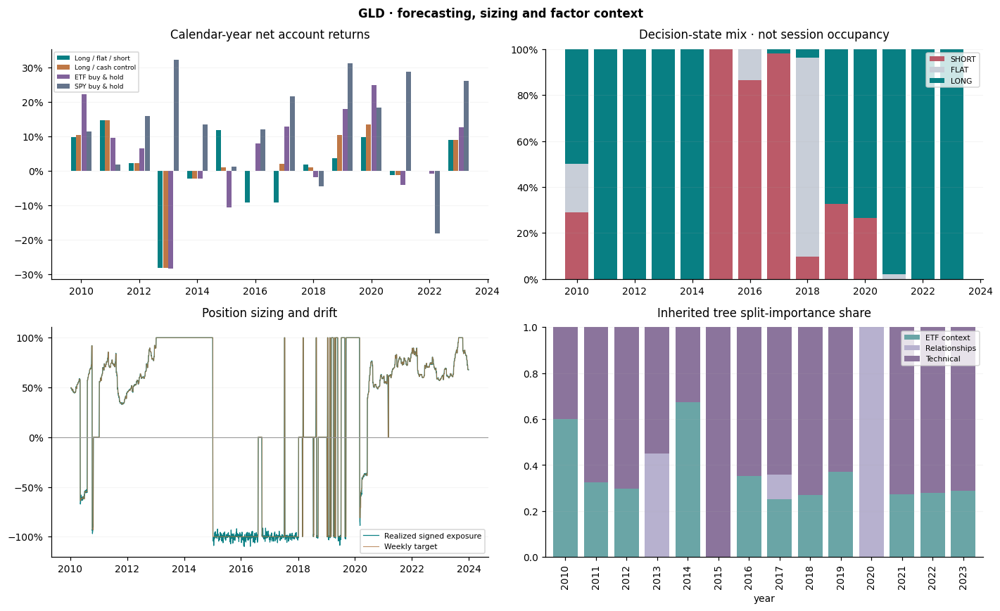

In [48]:
R.individual_diagnostics('GLD')

## DBC · account, trades and model context

All four accounts use matching dates within this ETF. Equity starts at NAV 1 immediately before the first included open; first-session returns and fees are retained.

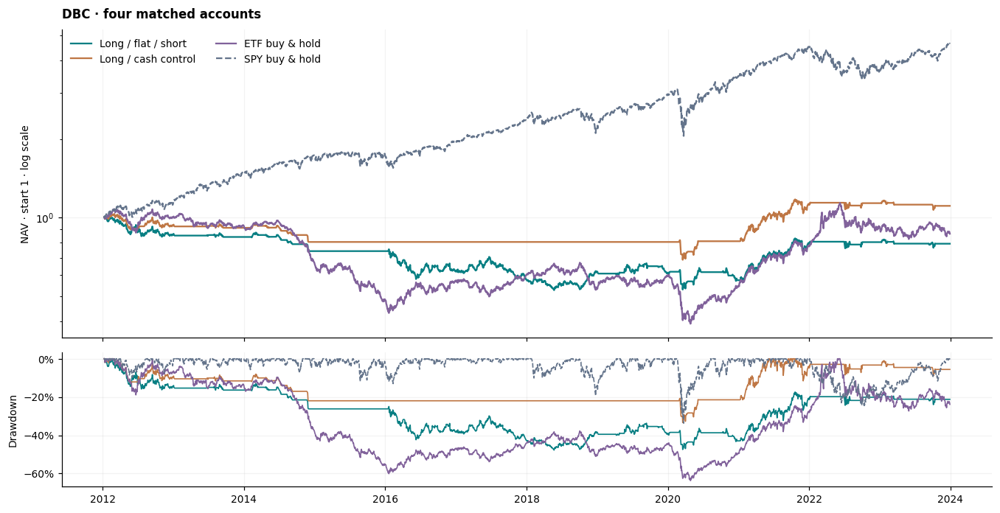

In [49]:
R.equity_figure('DBC')

In [50]:
display(HTML(R.individual_details('DBC')))

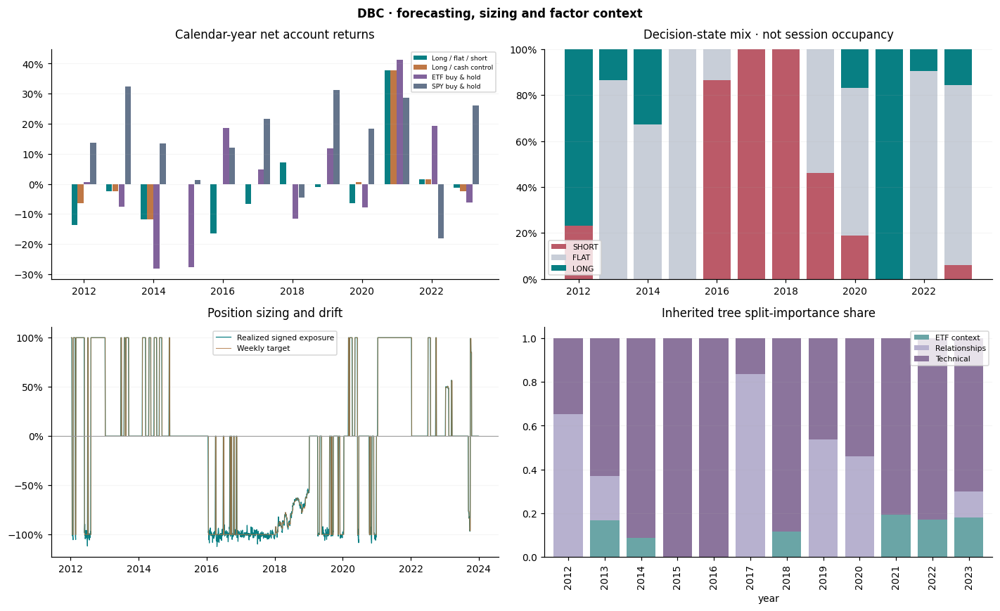

In [51]:
R.individual_diagnostics('DBC')

## VNQ · account, trades and model context

All four accounts use matching dates within this ETF. Equity starts at NAV 1 immediately before the first included open; first-session returns and fees are retained.

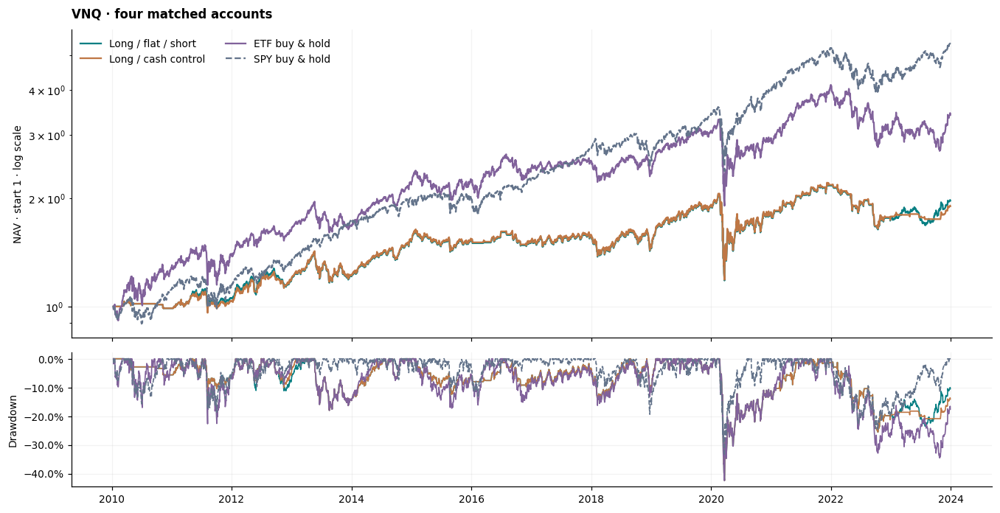

In [52]:
R.equity_figure('VNQ')

In [53]:
display(HTML(R.individual_details('VNQ')))

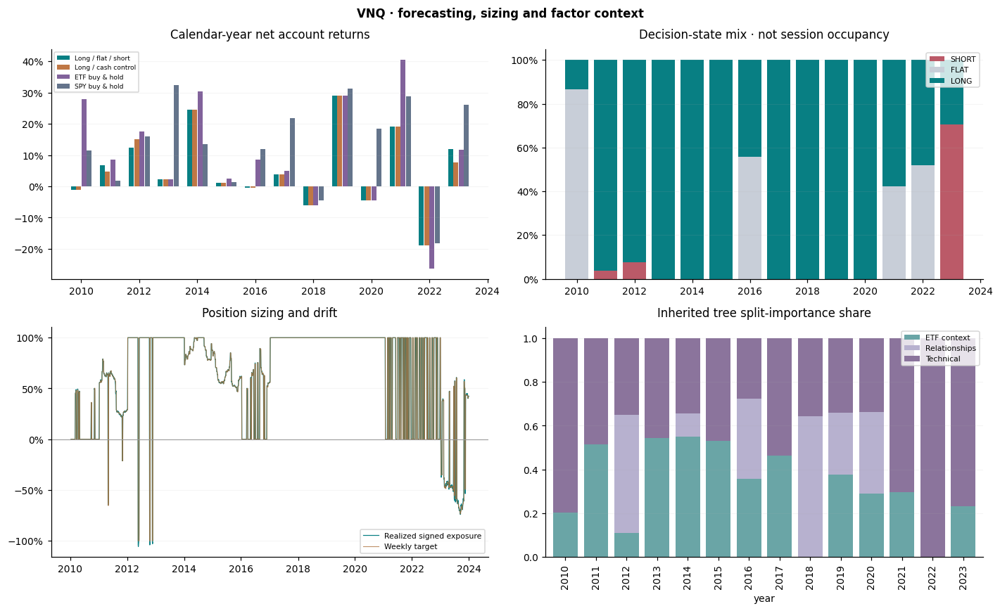

In [54]:
R.individual_diagnostics('VNQ')

## Interpretation limits and next validation

- Sharpe differences are measured on saved historical returns. A higher episode win rate does not
  by itself imply a higher Sharpe, larger return or smaller drawdown.
- Long and short P&L, holding duration, exposure and transaction costs should be read together.
  A short adds a new loss path during rebounds; cash in the original system was a valid decision.
- Borrowing interest was explicitly excluded. The net results include transaction fees but do not
  establish implementable returns after stock-loan charges or historical borrow constraints.
- Targets are capped, but intervening exposure drifts. Margin is observed only at the recorded
  open/close, not through the intraday path. Forced covering charges fees; a pooled account sells
  the minimum long value needed to avoid cash borrowing. Insolvent arms fail explicitly.
- Price-based ETF context does not become direct economic data: TIP–IEF is not measured inflation,
  TLT–IEF is not an observed yield curve and commodity proxies do not provide futures carry.
- The current ETF cohort and retrospective vendor adjustments retain survivorship/revision and
  corporate-action limitations, including XLF's 2016 distribution. Adjusted short units are a proxy.
- The trees, earlier specifications and this extension were developed with inspected pre-2024
  history. Fixed-fit uncertainty does not replay that selection. A later frozen validation process
  is needed; no reserved-period strategy score is generated here.


## Protocol and verification

In [55]:
display(HTML(R.provenance()))

File,Recorded status,Checks
reports/audit_report.json,PASS,2684
run_manifest.json,audited_backtests_complete,see file
